In [8]:
!pip install "gymnasium[atari,accept-rom-license]"

In [ ]:
!pip install autorom[accept-rom-license]
!AutoROM --accept-license

In [ ]:
!pip install ale-py

In [ ]:
!pip install autorom[accept-rom-license]
!AutoROM --accept-license

### Loading the Breakout Environment
Now we can initialize and test the `ALE/Breakout-v5` environment with a random action baseline.

In [9]:
import gymnasium as gym

# Create the Breakout environment
# We use 'rgb_array' render mode because we are running in a headless server environment (Colab)
env = gym.make("ALE/Breakout-v5", render_mode="rgb_array")

state, info = env.reset()
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)
print("Action Meanings:", env.unwrapped.get_action_meanings())

NamespaceNotFound: Namespace ALE not found. Have you installed the proper package for ALE?

### Run Random Actions in Breakout
Now we will initialize the environment again and run a basic loop where the agent performs random actions in the Breakout environment.

In [ ]:
import gymnasium as gym
import random

# Re-initialize the environment after ROM setup
env = gym.make("ALE/Breakout-v5", render_mode="rgb_array")

state, info = env.reset()

episodes = 5
for episode in range(1, episodes + 1):
    state, info = env.reset()
    done = False
    score = 0

    while not done:
        action = env.action_space.sample()  # Take a random action
        observation, reward, terminated, truncated, info = env.step(action)
        score += reward
        done = terminated or truncated

    print(f"Episode: {episode}, Score: {score}")

env.close()

### Visualizing the Environment using Matplotlib
Because Google Colab runs headlessly, we cannot use `env.render()` directly. Instead, we capture the RGB frames returned by the environment and render them in the notebook using `matplotlib` and `IPython.display`.

Episode Finished! Total Score: 1.0


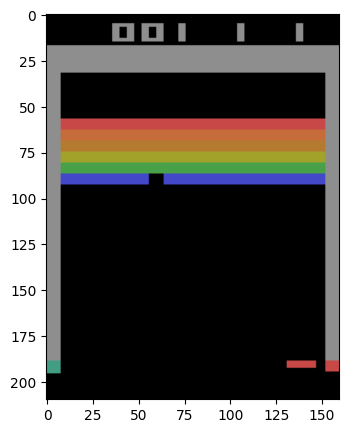

In [11]:
import gymnasium as gym
import ale_py
import matplotlib.pyplot as plt
from IPython import display

# Register ALE environments explicitly by importing ale_py
env = gym.make("ALE/Breakout-v5", render_mode="rgb_array")
state, info = env.reset()

plt.figure(figsize=(5, 5))
img = plt.imshow(env.render())

done = False
score = 0

while not done:
    action = env.action_space.sample()  # Select a random action
    observation, reward, terminated, truncated, info = env.step(action)
    score += reward
    done = terminated or truncated

    # Capture current frame and update the plot
    frame = env.render()
    img.set_data(frame)
    display.display(plt.gcf())
    display.clear_output(wait=True)

print(f"Episode Finished! Total Score: {score}")
env.close()

In [12]:
!pip install stable-baselines3[extra] shimmy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 9.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [stable-baselines3]


### Training DQN with Stable-Baselines3
We will initialize the Breakout environment with the proper Atari wrappers (using `make_atari_env` and `VecFrameStack` provided by Stable-Baselines3) to downscale the frames to 84x84 grayscale and stack them. Then we instantiate a DQN model and start a short training run.

In [13]:
import ale_py
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack

# Stable-Baselines3 provides helper functions to create wrapped Atari environments
env = make_atari_env("ALE/Breakout-v5", n_envs=1, seed=0)
# Stack 4 frames to help the model perceive motion (velocity)
env = VecFrameStack(env, n_stack=4)

# Initialize DQN agent with CnnPolicy because the observations are image frames
model = DQN(
    "CnnPolicy",
    env,
    verbose=1,
    buffer_size=10000,          # Reduced buffer size for quick demonstration in Colab
    learning_rate=1e-4,
    batch_size=32,
    learning_starts=1000,
    target_update_interval=1000,
    train_freq=4,
    exploration_fraction=0.1,
    exploration_final_eps=0.01,
    device="auto"               # Uses GPU automatically if available in Colab
)

# Train the agent for 10,000 timesteps to see the training loop in action
model.learn(total_timesteps=10000, log_interval=10)

# Save the trained model
model.save("dqn_breakout")
print("Model training complete and saved!")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Using cpu device
Wrapping the env in a VecTransposeImage.
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 288      |
|    ep_rew_mean      | 3.5      |
|    exploration_rate | 0.889    |
| time/               |          |
|    episodes         | 10       |
|    fps              | 160      |
|    time_elapsed     | 0        |
|    total_timesteps  | 112      |
----------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 294      |
|    ep_rew_mean      | 3.5      |
|    exploration_rate | 0.775    |
| time/               |          |
|    episodes         | 20       |
|    fps              | 191      |
|    time_elapsed     | 1        |
|    total_timesteps  | 227      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 291      |
|    ep_rew_mean      | 3.5      |
|    exploration_rate | 0.669    |
| time/               |          |
|    episodes         | 30       |
|    fps              | 201      |
|    time_elapsed     | 1        |
|    total_timesteps  | 334      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 276      |
|    ep_rew_mean      | 3.12     |
|    exploration_rate | 0.583    |
| time/               |          |
|    episodes       

### Visualizing the Trained Agent
Let's load our saved model `dqn_breakout` and run a gameplay session. We will capture the wrapped environment's render frames and visualize the DQN agent's decision-making.

Episode Finished! Total Score: 0.0


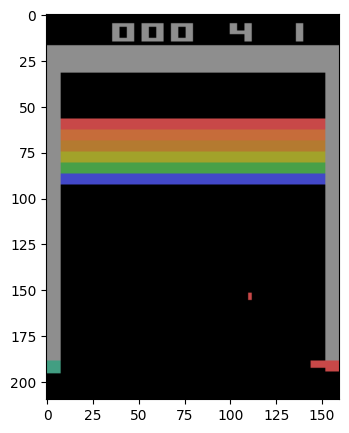

In [14]:
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack
import matplotlib.pyplot as plt
from IPython import display
import time

# Recreate the wrapped environment for evaluation
eval_env = make_atari_env("ALE/Breakout-v5", n_envs=1, seed=42)
eval_env = VecFrameStack(eval_env, n_stack=4)

# Load our trained DQN model
model = DQN.load("dqn_breakout", env=eval_env)

obs = eval_env.reset()
plt.figure(figsize=(5, 5))

# Capture and plot the initial frame
img = plt.imshow(eval_env.render())

done = False
total_reward = 0

while not done:
    # Predict the best action using the trained model
    action, _states = model.predict(obs, deterministic=True)
    obs, rewards, dones, infos = eval_env.step(action)
    total_reward += rewards[0]
    done = dones[0]

    # Render and animate the frame in the notebook
    frame = eval_env.render()
    img.set_data(frame)
    display.display(plt.gcf())
    display.clear_output(wait=True)
    time.sleep(0.01) # Small delay to make the animation smoother

print(f"Episode Finished! Total Score: {total_reward}")
eval_env.close()

### Fine-Tuning DQN Hyperparameters

To improve our agent's playing performance, we will adjust several key hyperparameters of the DQN model:

* **Learning Rate (`learning_rate`)**: Adjusted to `1e-4` for stable convergence.
* **Replay Buffer Size (`buffer_size`)**: Increased to `50,000` to store more transitions and learn from diverse experiences.
* **Exploration (`exploration_fraction`)**: Set to dynamically decrease exploration over the first 10% of training steps down to a minimum rate of `0.01` to encourage exploitation as learning progresses.
* **Target Network Update (`target_update_interval`)**: Updated to update target networks every `1,000` steps.
* **Training Timesteps**: Increased to allow the agent to learn the mechanics of hitting the ball.

In [15]:
import ale_py
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack

# Set up the environment with standardized Atari wrappers
env = make_atari_env("ALE/Breakout-v5", n_envs=1, seed=123)
env = VecFrameStack(env, n_stack=4)

# Configure hyperparameter-optimized DQN Agent
optimized_model = DQN(
    "CnnPolicy",
    env,
    verbose=1,
    buffer_size=50000,           # Increased memory buffer
    learning_rate=1e-4,          # Stable learning rate
    batch_size=32,               # Standard mini-batch size
    learning_starts=5000,        # Collect historical data before training
    target_update_interval=1000, # Frequency of target network sync
    train_freq=4,                # Number of steps between gradient updates
    exploration_fraction=0.15,   # Percent of steps to decay exploration
    exploration_final_eps=0.01,  # Final exploration minimum rate
    device="auto"                # Uses GPU if available
)

# Train optimized model (Increase timesteps for better results)
print("Training optimized model...")
optimized_model.learn(total_timesteps=30000, log_interval=20)

# Save the fine-tuned model
optimized_model.save("dqn_breakout_optimized")
print("Optimized model training complete and saved!")

Using cpu device
Wrapping the env in a VecTransposeImage.
Training optimized model...
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 249      |
|    ep_rew_mean      | 2.5      |
|    exploration_rate | 0.958    |
| time/               |          |
|    episodes         | 20       |
|    fps              | 187      |
|    time_elapsed     | 1        |
|    total_timesteps  | 190      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 273      |
|    ep_rew_mean      | 3.25     |
|    exploration_rate | 0.908    |
| time/               |          |
|    episodes         | 40       |
|    fps              | 209      |
|    time_elapsed     | 1        |
|    total_timesteps  | 417      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 282      |
|    ep_rew_mean      | 3.25     |
|   

### Visualizing our Fine-Tuned DQN Agent
Let's load the optimized model (`dqn_breakout_optimized`) and see how well it plays compared to our first basic agent.

Optimized Model Finished! Total Score: 4.0


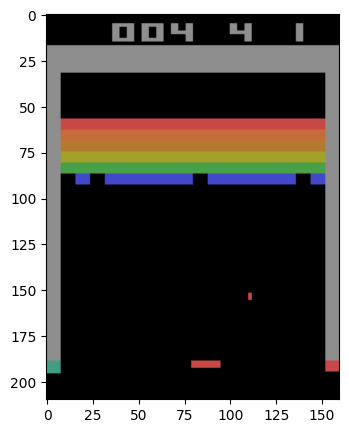

In [16]:
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack
import matplotlib.pyplot as plt
from IPython import display
import time

# Recreate the wrapped environment for evaluation
eval_env = make_atari_env("ALE/Breakout-v5", n_envs=1, seed=123)
eval_env = VecFrameStack(eval_env, n_stack=4)

# Load our optimized DQN model
optimized_model = DQN.load("dqn_breakout_optimized", env=eval_env)

obs = eval_env.reset()
plt.figure(figsize=(5, 5))

# Capture and plot the initial frame
img = plt.imshow(eval_env.render())

done = False
total_reward = 0

while not done:
    # Predict using the optimized model
    action, _states = optimized_model.predict(obs, deterministic=True)
    obs, rewards, dones, infos = eval_env.step(action)
    total_reward += rewards[0]
    done = dones[0]

    # Render the frames inside Colab
    frame = eval_env.render()
    img.set_data(frame)
    display.display(plt.gcf())
    display.clear_output(wait=True)
    time.sleep(0.01)

print(f"Optimized Model Finished! Total Score: {total_reward}")
eval_env.close()